# 3.1.4. Задача классификации

## Прогнозирование поломки промышленного оборудования

В работе используется датасет, сформированный из базы данных `manufacturing`.

Цель работы — построить модель бинарной классификации, которая по известным на момент прогнозирования характеристикам оборудования и показаниям датчиков определяет, произойдёт ли поломка оборудования в следующие 6 часов.

Целевая переменная:

- `failure_next_6h = 1` — в следующие 6 часов произойдёт поломка;
- `failure_next_6h = 0` — в следующие 6 часов поломки не будет.

Для решения задачи используется алгоритм K-ближайших соседей — `KNeighborsClassifier`.

В работе будут выполнены:

- анализ целевой переменной и признаков;
- подготовка и масштабирование данных;
- хронологическое разделение на обучающую и тестовую выборки;
- обучение KNN с разным количеством соседей;
- построение Precision–Recall и ROC-кривых;
- выбор порога классификации;
- построение матрицы ошибок;
- расчёт метрик качества;
- содержательная интерпретация результата.

Импорт библиотек

In [2]:
from pathlib import Path
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

from sklearn.impute import SimpleImputer
from sklearn.preprocessing import (
    OneHotEncoder,
    StandardScaler
)

from sklearn.neighbors import KNeighborsClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix,
    ConfusionMatrixDisplay,
    classification_report,
    precision_recall_curve,
    roc_curve
)

warnings.filterwarnings("ignore")

pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", lambda x: f"{x:.4f}")

sns.set_theme(
    style="whitegrid",
    palette="deep"
)

RANDOM_STATE = 42

Загрузка данных

In [3]:
DATA_PATH = Path(
    "/home/lova595/Рабочий стол/иннополис/"
    "база данных/manufacturing_ml_dataset.csv"
)

if not DATA_PATH.exists():
    raise FileNotFoundError(
        f"Файл не найден: {DATA_PATH}\n"
        "Проверьте путь к manufacturing_ml_dataset.csv."
    )

df = pd.read_csv(
    DATA_PATH,
    parse_dates=["prediction_time"]
)

print(
    f"Размер исходной таблицы: "
    f"{df.shape[0]:,} строк × {df.shape[1]} столбцов"
)

display(df.head())

Размер исходной таблицы: 17,403 строк × 40 столбцов


,machine_id,machine_code,machine_type_code,line_id,prediction_time,machine_age_years,nominal_power_kw,readings_count_1h,out_of_range_count_1h,temperature_avg_1h,temperature_min_1h,temperature_max_1h,temperature_std_1h,temperature_out_of_range_1h,vibration_avg_1h,vibration_min_1h,vibration_max_1h,vibration_std_1h,vibration_out_of_range_1h,power_avg_1h,power_min_1h,power_max_1h,power_std_1h,rpm_avg_1h,rpm_min_1h,rpm_max_1h,rpm_std_1h,pressure_avg_1h,pressure_min_1h,pressure_max_1h,pressure_std_1h,humidity_avg_1h,humidity_min_1h,humidity_max_1h,humidity_std_1h,breakdowns_before,hours_since_last_breakdown,maintenance_last_30d,hours_since_last_maintenance,failure_next_6h
0,29,M-008-01,CNC_MILL,8,2025-01-10 16:00:00+11:00,3.3370,22.0000,136,0,65.7356,55.1603,80.3652,5.3848,0,2.4075,1.1127,3.5109,0.6082,0,1.2232,1.0226,1.4437,0.0962,2444.2909,2153.6655,2776.9232,147.8383,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0,NaN,0,NaN,0
1,2,M-001-02,PRESS,1,2025-01-10 17:00:00+11:00,6.5050,30.0000,205,0,69.8676,55.1643,85.3239,6.2580,0,NaN,NaN,NaN,NaN,0,1.9018,1.7123,2.1424,0.1021,NaN,NaN,NaN,NaN,81.1822,74.4858,90.2300,3.7037,NaN,NaN,NaN,NaN,0,NaN,0,NaN,0
2,4,M-001-04,CNC_MILL,1,2025-01-10 17:00:00+11:00,3.8440,22.0000,68,0,64.5500,53.8869,78.3736,6.4092,0,2.3260,1.7124,3.1240,0.3885,0,1.1603,1.0792,1.2380,0.0500,2413.8897,2152.2816,2678.2842,163.1264,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0,NaN,0,NaN,0
3,29,M-008-01,CNC_MILL,8,2025-01-10 17:00:00+11:00,3.3380,22.0000,232,0,68.5656,55.9920,91.6056,5.8926,0,2.5250,1.6584,3.6639,0.4728,0,1.2901,1.1101,1.4714,0.0926,2496.6064,2255.5292,2882.5159,134.8627,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0,NaN,0,NaN,0
4,4,M-001-04,CNC_MILL,1,2025-01-10 18:00:00+11:00,3.8440,22.0000,172,0,66.2371,56.5269,74.5081,5.0304,0,2.4612,1.0851,3.4731,0.5089,0,1.2215,1.0615,1.3548,0.0663,2521.2391,2109.1175,2951.5062,169.6876,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0,NaN,0,NaN,0


## Выбор переменных

### Целевая переменная

`failure_next_6h` показывает, произойдёт ли аварийная поломка оборудования в следующие 6 часов.

### Объясняющие признаки

Для построения модели используются только сведения, доступные на момент формирования прогноза:

- возраст оборудования;
- номинальная мощность;
- количество показаний за последний час;
- количество показаний за допустимыми границами;
- средняя температура;
- средняя фактическая мощность;
- количество предыдущих поломок;
- время после предыдущей поломки;
- количество обслуживаний за последние 30 дней;
- время после последнего обслуживания;
- тип оборудования.

Идентификаторы `machine_id`, `machine_code` и `line_id` не используются, поскольку они обозначают объекты, но не характеризуют их техническое состояние.

В модели также не используются сведения о будущих событиях и признаки, непосредственно сообщающие о произошедшей поломке. Это предотвращает утечку целевой переменной.

In [4]:
TARGET = "failure_next_6h"

NUMERIC_FEATURES = [
    "machine_age_years",
    "nominal_power_kw",
    "readings_count_1h",
    "out_of_range_count_1h",
    "temperature_avg_1h",
    "power_avg_1h",
    "breakdowns_before",
    "hours_since_last_breakdown",
    "maintenance_last_30d",
    "hours_since_last_maintenance",
]

CATEGORICAL_FEATURES = [
    "machine_type_code",
]

FEATURES = (
    NUMERIC_FEATURES
    + CATEGORICAL_FEATURES
)

classification_df = df[
    ["prediction_time", TARGET] + FEATURES
].copy()

print("Целевая переменная:")
print(TARGET)

print("\nЧисловые признаки:")
for feature in NUMERIC_FEATURES:
    print("-", feature)

print("\nКатегориальные признаки:")
for feature in CATEGORICAL_FEATURES:
    print("-", feature)

display(classification_df.head())

Целевая переменная:
failure_next_6h

Числовые признаки:
- machine_age_years
- nominal_power_kw
- readings_count_1h
- out_of_range_count_1h
- temperature_avg_1h
- power_avg_1h
- breakdowns_before
- hours_since_last_breakdown
- maintenance_last_30d
- hours_since_last_maintenance

Категориальные признаки:
- machine_type_code


,prediction_time,failure_next_6h,machine_age_years,nominal_power_kw,readings_count_1h,out_of_range_count_1h,temperature_avg_1h,power_avg_1h,breakdowns_before,hours_since_last_breakdown,maintenance_last_30d,hours_since_last_maintenance,machine_type_code
0,2025-01-10 16:00:00+11:00,0,3.3370,22.0000,136,0,65.7356,1.2232,0,NaN,0,NaN,CNC_MILL
1,2025-01-10 17:00:00+11:00,0,6.5050,30.0000,205,0,69.8676,1.9018,0,NaN,0,NaN,PRESS
2,2025-01-10 17:00:00+11:00,0,3.8440,22.0000,68,0,64.5500,1.1603,0,NaN,0,NaN,CNC_MILL
3,2025-01-10 17:00:00+11:00,0,3.3380,22.0000,232,0,68.5656,1.2901,0,NaN,0,NaN,CNC_MILL
4,2025-01-10 18:00:00+11:00,0,3.8440,22.0000,172,0,66.2371,1.2215,0,NaN,0,NaN,CNC_MILL


Проверка целевой переменной

In [5]:
target_distribution = (
    classification_df[TARGET]
    .value_counts()
    .sort_index()
    .rename_axis("class")
    .reset_index(name="observations")
)

target_distribution["percent"] = (
    target_distribution["observations"]
    / len(classification_df)
    * 100
)

target_distribution["class_name"] = (
    target_distribution["class"]
    .map({
        0: "Поломки не будет",
        1: "Поломка в следующие 6 часов"
    })
)

display(target_distribution)

,class,observations,percent,class_name
0,0,17133,98.4485,Поломки не будет
1,1,270,1.5515,Поломка в следующие 6 часов


In [6]:
assert classification_df[TARGET].isna().sum() == 0
assert set(classification_df[TARGET].unique()) == {0, 1}

negative_count = (
    classification_df[TARGET] == 0
).sum()

positive_count = (
    classification_df[TARGET] == 1
).sum()

positive_percent = (
    classification_df[TARGET].mean() * 100
)

print(f"Класс 0: {negative_count:,} наблюдений")
print(f"Класс 1: {positive_count:,} наблюдений")
print(f"Доля поломок: {positive_percent:.4f}%")

Класс 0: 17,133 наблюдений
Класс 1: 270 наблюдений
Доля поломок: 1.5515%


Визуализация баланса классов

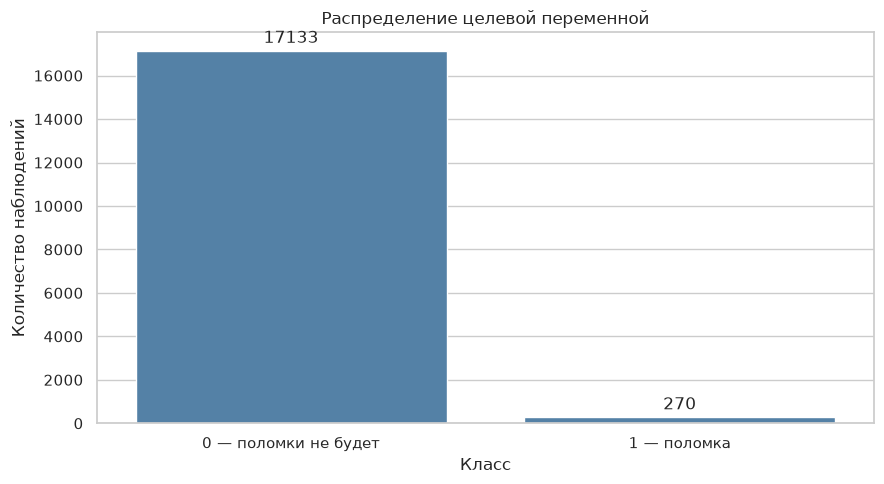

In [7]:
plt.figure(figsize=(9, 5))

ax = sns.countplot(
    data=classification_df,
    x=TARGET,
    color="steelblue"
)

ax.set_title(
    "Распределение целевой переменной"
)
ax.set_xlabel("Класс")
ax.set_ylabel("Количество наблюдений")
ax.set_xticklabels([
    "0 — поломки не будет",
    "1 — поломка"
])

for container in ax.containers:
    ax.bar_label(
        container,
        fmt="%d",
        padding=3
    )

plt.tight_layout()
plt.show()

Проверка пропусков

In [8]:
missing_values = (
    classification_df
    .isna()
    .sum()
    .rename("missing_count")
    .to_frame()
)

missing_values["missing_percent"] = (
    missing_values["missing_count"]
    / len(classification_df)
    * 100
)

missing_values = (
    missing_values
    .sort_values(
        "missing_count",
        ascending=False
    )
)

display(missing_values)

,missing_count,missing_percent
hours_since_last_maintenance,8897,51.1234
hours_since_last_breakdown,8854,50.8763
power_avg_1h,46,0.2643
failure_next_6h,0,0.0000
prediction_time,0,0.0000
readings_count_1h,0,0.0000
nominal_power_kw,0,0.0000
machine_age_years,0,0.0000
out_of_range_count_1h,0,0.0000
breakdowns_before,0,0.0000


### Вывод по целевой переменной и подготовке данных

В датасете содержится 17 403 наблюдения. Целевая переменная `failure_next_6h` уже имеет бинарный формат и не содержит пропусков.

Класс `1`, соответствующий поломке в следующие 6 часов, встречается только в 270 наблюдениях — приблизительно в 1,55% выборки. Следовательно, целевая переменная имеет выраженный дисбаланс классов.

Из-за дисбаланса accuracy не может быть основной метрикой качества. Если модель всегда будет предсказывать отсутствие поломки, её accuracy составит около 98,45%, однако она не обнаружит ни одной реальной поломки.

Поэтому основными метриками будут:

- Recall — доля обнаруженных поломок;
- Precision — доля настоящих поломок среди предупреждений модели;
- F1-score — баланс Precision и Recall;
- PR-AUC — качество ранжирования редкого положительного класса;
- ROC-AUC — способность модели разделять два класса.

Пропуски в объясняющих признаках не удаляются. Они будут обработаны внутри обучающего пайплайна, чтобы не допустить утечки информации из тестовой выборки.

## Исследование связи признаков с целевой переменной

Сравним значения числовых признаков для двух классов:

- класс 0 — в следующие 6 часов поломки не будет;
- класс 1 — в следующие 6 часов произойдёт поломка.

Если распределения признака заметно различаются между классами, он может быть полезен для классификации.

In [9]:
mean_by_class = (
    classification_df
    .groupby(TARGET)[NUMERIC_FEATURES]
    .mean()
    .T
)

mean_by_class.columns = [
    "mean_class_0",
    "mean_class_1"
]

mean_by_class["difference"] = (
    mean_by_class["mean_class_1"]
    - mean_by_class["mean_class_0"]
)

mean_by_class["difference_percent"] = (
    mean_by_class["difference"]
    / mean_by_class["mean_class_0"]
    * 100
)

display(
    mean_by_class.style.format({
        "mean_class_0": "{:.3f}",
        "mean_class_1": "{:.3f}",
        "difference": "{:.3f}",
        "difference_percent": "{:.2f}%"
    })
)

,mean_class_0,mean_class_1,difference,difference_percent
machine_age_years,4.949,5.108,0.159,3.20%
nominal_power_kw,26.416,26.609,0.193,0.73%
readings_count_1h,130.541,124.437,-6.104,-4.68%
out_of_range_count_1h,7.174,7.119,-0.056,-0.77%
temperature_avg_1h,88.003,87.723,-0.279,-0.32%
power_avg_1h,2.501,2.358,-0.143,-5.72%
breakdowns_before,0.771,0.819,0.047,6.10%
hours_since_last_breakdown,1014.628,1093.340,78.712,7.76%
maintenance_last_30d,0.246,0.259,0.013,5.38%
hours_since_last_maintenance,1022.998,1091.782,68.784,6.72%


Boxplot числовых признаков

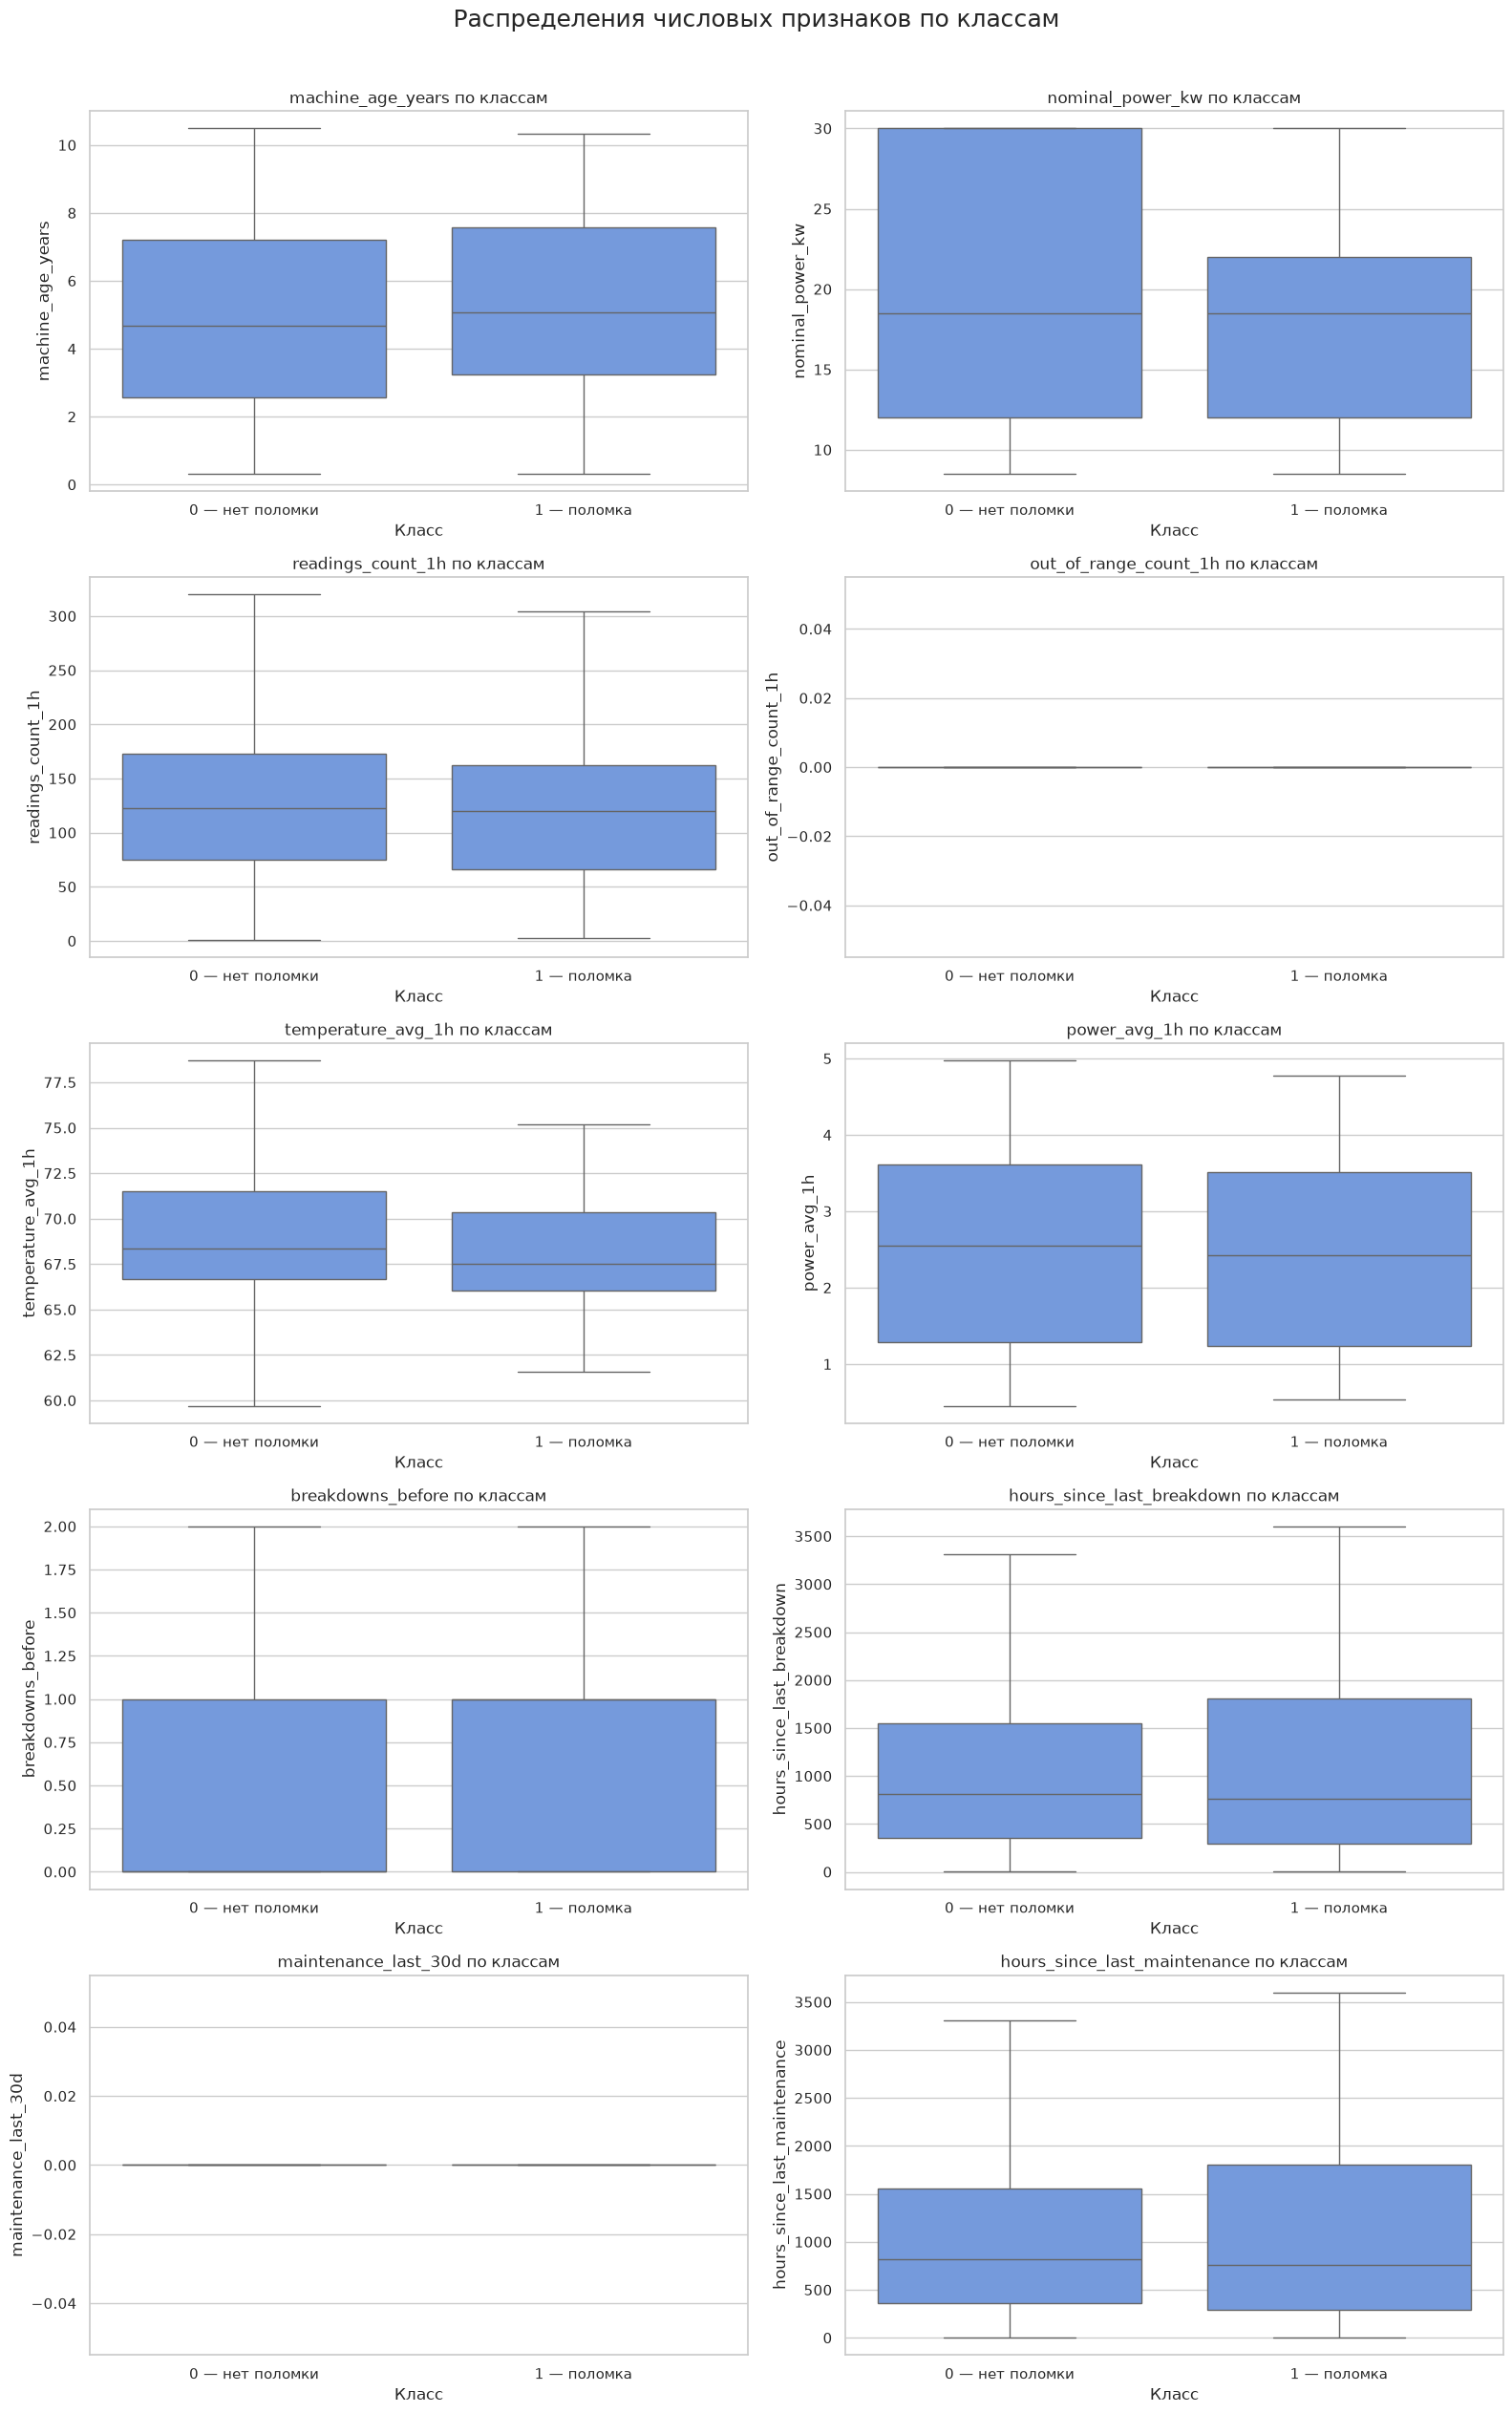

In [10]:
fig, axes = plt.subplots(
    nrows=5,
    ncols=2,
    figsize=(16, 25)
)

axes = axes.ravel()

for ax, feature in zip(
    axes,
    NUMERIC_FEATURES
):
    sns.boxplot(
        data=classification_df,
        x=TARGET,
        y=feature,
        showfliers=False,
        color="cornflowerblue",
        ax=ax
    )

    ax.set_title(
        f"{feature} по классам"
    )
    ax.set_xlabel("Класс")
    ax.set_ylabel(feature)
    ax.set_xticklabels([
        "0 — нет поломки",
        "1 — поломка"
    ])

plt.suptitle(
    "Распределения числовых признаков по классам",
    fontsize=18,
    y=1.01
)

plt.tight_layout()
plt.show()

На boxplot отключено отображение отдельных выбросов с помощью `showfliers=False`. Значения не удаляются из датасета — это сделано только для повышения читаемости графиков.

Точечная диаграмма

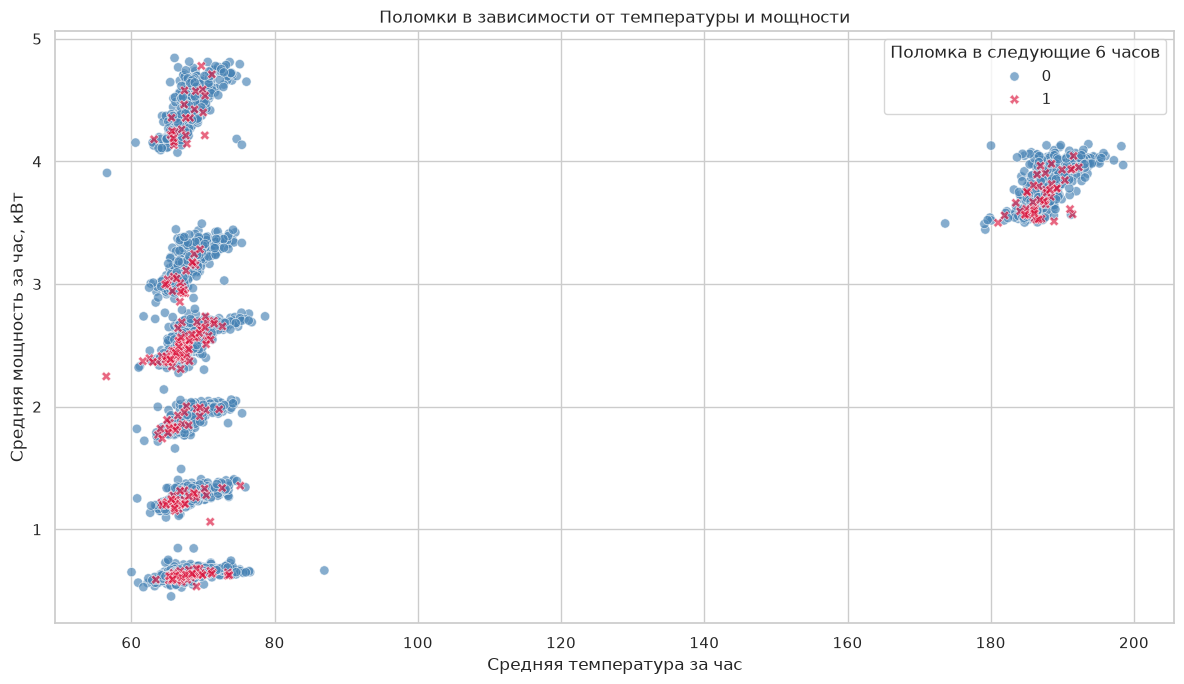

In [11]:
negative_plot_sample = (
    classification_df[
        classification_df[TARGET] == 0
    ]
    .sample(
        n=3000,
        random_state=RANDOM_STATE
    )
)

positive_plot_sample = classification_df[
    classification_df[TARGET] == 1
]

scatter_df = pd.concat(
    [
        negative_plot_sample,
        positive_plot_sample
    ],
    ignore_index=True
)

plt.figure(figsize=(12, 7))

sns.scatterplot(
    data=scatter_df,
    x="temperature_avg_1h",
    y="power_avg_1h",
    hue=TARGET,
    style=TARGET,
    palette={
        0: "steelblue",
        1: "crimson"
    },
    alpha=0.65,
    s=45
)

plt.title(
    "Поломки в зависимости от температуры и мощности"
)
plt.xlabel("Средняя температура за час")
plt.ylabel("Средняя мощность за час, кВт")

plt.legend(
    title="Поломка в следующие 6 часов"
)

plt.tight_layout()
plt.show()

На диаграмме положительный и отрицательный классы существенно перекрываются. По одной только температуре и мощности нельзя провести чёткую границу между состояниями оборудования.

Следовательно, классификация должна учитывать одновременно несколько признаков. KNN будет определять класс на основании совокупного расстояния между объектами в многомерном пространстве.

Частота поломок по типам оборудования

In [12]:
failure_by_machine_type = (
    classification_df
    .groupby("machine_type_code")
    .agg(
        observations=(TARGET, "size"),
        failures=(TARGET, "sum"),
        failure_rate=(TARGET, "mean")
    )
    .reset_index()
)

failure_by_machine_type[
    "failure_rate_percent"
] = (
    failure_by_machine_type["failure_rate"]
    * 100
)

failure_by_machine_type = (
    failure_by_machine_type
    .sort_values(
        "failure_rate_percent",
        ascending=False
    )
)

display(
    failure_by_machine_type.style.format({
        "failure_rate": "{:.4f}",
        "failure_rate_percent": "{:.2f}%"
    })
)

,machine_type_code,observations,failures,failure_rate,failure_rate_percent
5,ROBOT,3767,77,0.0204,2.04%
1,CNC_MILL,1991,37,0.0186,1.86%
2,OVEN,2886,46,0.0159,1.59%
0,CNC_LATHE,3117,46,0.0148,1.48%
4,PRESS,1508,21,0.0139,1.39%
3,PACK,1964,23,0.0117,1.17%
6,WELDER,2170,20,0.0092,0.92%


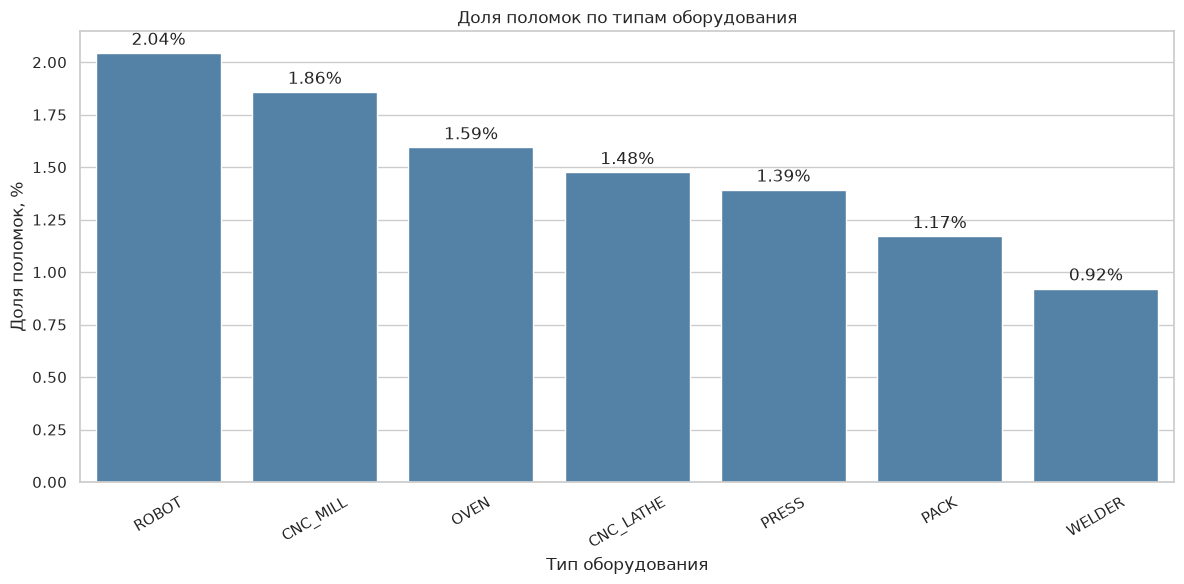

In [13]:
plt.figure(figsize=(12, 6))

ax = sns.barplot(
    data=failure_by_machine_type,
    x="machine_type_code",
    y="failure_rate_percent",
    color="steelblue"
)

ax.set_title(
    "Доля поломок по типам оборудования"
)
ax.set_xlabel("Тип оборудования")
ax.set_ylabel("Доля поломок, %")

plt.xticks(rotation=30)

for container in ax.containers:
    ax.bar_label(
        container,
        fmt="%.2f%%",
        padding=3
    )

plt.tight_layout()
plt.show()

### Вывод по исследованию признаков

Распределения большинства числовых признаков для классов 0 и 1 значительно перекрываются. Средние значения температуры, номинальной мощности, возраста оборудования и количества выходов за допустимые границы отличаются незначительно.

Наиболее заметные, хотя и слабые, различия связаны с:

- количеством показаний за час;
- средней фактической мощностью;
- количеством предыдущих поломок;
- временем после предыдущей поломки;
- типом оборудования.

Доля поломок различается между типами оборудования. Наибольшая доля наблюдается у оборудования типа `ROBOT`, а наименьшая — у `WELDER`. Поэтому категориальный признак `machine_type_code` целесообразно включить в модель.

На точечной диаграмме классы не образуют отдельных компактных областей. Это показывает, что задача классификации является сложной: положительный класс нельзя определить по одному признаку или простой границе.

Кроме того, положительный класс составляет только около 1,55% наблюдений. Поэтому модель может показывать высокую accuracy, но при этом не обнаруживать реальные поломки. Основное внимание необходимо уделять Recall, Precision, F1 и PR-AUC.

## Разделение на обучающую и тестовую выборки

Датасет представляет собой последовательность наблюдений во времени. Поэтому случайное перемешивание не используется.

Первые 80% временных точек используются для обучения, последние 20% — для тестирования. Это соответствует практическому сценарию, в котором модель обучается на прошлых данных и прогнозирует будущие поломки.

In [14]:
classification_df = (
    classification_df
    .sort_values("prediction_time")
    .reset_index(drop=True)
)

unique_times = np.sort(
    classification_df[
        "prediction_time"
    ].unique()
)

cutoff_index = int(
    len(unique_times) * 0.80
)

cutoff_time = unique_times[
    cutoff_index
]

train_df = classification_df[
    classification_df["prediction_time"]
    < cutoff_time
].copy()

test_df = classification_df[
    classification_df["prediction_time"]
    >= cutoff_time
].copy()

X_train = train_df[FEATURES]
y_train = train_df[TARGET]

X_test = test_df[FEATURES]
y_test = test_df[TARGET]

print("Граница разделения:", cutoff_time)
print()

print(
    f"Обучающая выборка: "
    f"{len(train_df):,} строк"
)

print(
    f"Тестовая выборка: "
    f"{len(test_df):,} строк"
)

print()
print(
    "Период train:",
    train_df["prediction_time"].min(),
    "—",
    train_df["prediction_time"].max()
)

print(
    "Период test:",
    test_df["prediction_time"].min(),
    "—",
    test_df["prediction_time"].max()
)

Граница разделения: 2025-05-28 09:00:00+11:00

Обучающая выборка: 13,728 строк
Тестовая выборка: 3,675 строк

Период train: 2025-01-10 16:00:00+11:00 — 2025-05-28 08:00:00+11:00
Период test: 2025-05-28 09:00:00+11:00 — 2025-07-01 00:00:00+11:00


Проверка баланса классов после разделения

In [15]:
def class_balance_table(target):
    result = (
        target
        .value_counts()
        .sort_index()
        .rename_axis("class")
        .reset_index(name="observations")
    )

    result["percent"] = (
        result["observations"]
        / len(target)
        * 100
    )

    return result


print("Обучающая выборка:")
display(class_balance_table(y_train))

print("Тестовая выборка:")
display(class_balance_table(y_test))

Обучающая выборка:


,class,observations,percent
0,0,13500,98.3392
1,1,228,1.6608


Тестовая выборка:


,class,observations,percent
0,0,3633,98.8571
1,1,42,1.1429


In [16]:
print(
    "Поломок в train:",
    int(y_train.sum())
)

print(
    "Поломок в test:",
    int(y_test.sum())
)

assert (
    train_df["prediction_time"].max()
    < test_df["prediction_time"].min()
)

assert y_train.sum() > 0
assert y_test.sum() > 0

print(
    "\nВременное разделение выполнено корректно."
)

Поломок в train: 228
Поломок в test: 42

Временное разделение выполнено корректно.


### Вывод

Данные разделены хронологически:

- обучающая выборка содержит 13 728 наблюдений и 228 поломок;
- тестовая выборка содержит 3 675 наблюдений и 42 поломки;
- граница разделения — 28 мая 2025 года.

Доля положительного класса в обучающей выборке составляет около 1,66%, а в тестовой — около 1,14%. Это означает, что в более позднем периоде поломки встречались немного реже.

Оба класса присутствуют в обучающей и тестовой выборках. Следовательно, можно обучать модель и рассчитывать метрики бинарной классификации.

Заполнение пропусков, кодирование типа оборудования и масштабирование пока не выполнялись. Эти операции будут включены в единый Pipeline и обучены только на обучающей выборке, что предотвращает утечку данных.

Выделение validation-выборки

## Подбор параметров модели

Тестовая выборка должна использоваться только для окончательной оценки модели. Поэтому обучающая выборка дополнительно разделяется по времени:

- `fit` — данные для обучения моделей;
- `validation` — данные для выбора количества соседей и способа взвешивания;
- `test` — данные для окончательной проверки.

Разделение выполняется без перемешивания.

In [17]:
train_unique_times = np.sort(
    train_df["prediction_time"].unique()
)

validation_cutoff_index = int(
    len(train_unique_times) * 0.80
)

validation_cutoff_time = train_unique_times[
    validation_cutoff_index
]

fit_df = train_df[
    train_df["prediction_time"]
    < validation_cutoff_time
].copy()

validation_df = train_df[
    train_df["prediction_time"]
    >= validation_cutoff_time
].copy()

X_fit = fit_df[FEATURES]
y_fit = fit_df[TARGET]

X_validation = validation_df[FEATURES]
y_validation = validation_df[TARGET]

print(
    "Граница fit/validation:",
    validation_cutoff_time
)

print(
    f"Fit: {len(fit_df):,} наблюдений, "
    f"поломок: {int(y_fit.sum())}"
)

print(
    f"Validation: {len(validation_df):,} наблюдений, "
    f"поломок: {int(y_validation.sum())}"
)

print(
    f"Test: {len(test_df):,} наблюдений, "
    f"поломок: {int(y_test.sum())}"
)

Граница fit/validation: 2025-04-30 16:00:00+11:00
Fit: 11,413 наблюдений, поломок: 182
Validation: 2,315 наблюдений, поломок: 46
Test: 3,675 наблюдений, поломок: 42


In [18]:
assert (
    fit_df["prediction_time"].max()
    < validation_df["prediction_time"].min()
)

assert (
    validation_df["prediction_time"].max()
    < test_df["prediction_time"].min()
)

print("Временной порядок выборок соблюдён.")

Временной порядок выборок соблюдён.


## Предобработка данных

Для числовых признаков выполняются:

1. заполнение пропусков медианой обучающей выборки;
2. добавление индикаторов пропусков;
3. стандартизация с помощью `StandardScaler`.

Для категориального признака выполняются:

1. заполнение пропусков наиболее частым значением;
2. One-Hot Encoding.

Масштабирование особенно важно для KNN, поскольку алгоритм основан на расстоянии между объектами. Без масштабирования признаки с большими числовыми значениями будут непропорционально сильно влиять на результат.

In [19]:
def create_preprocessor(scale_numeric=True):

    numeric_steps = [
        (
            "imputer",
            SimpleImputer(
                strategy="median",
                add_indicator=True
            )
        )
    ]

    if scale_numeric:
        numeric_steps.append(
            (
                "scaler",
                StandardScaler()
            )
        )

    numeric_transformer = Pipeline(
        steps=numeric_steps
    )

    categorical_transformer = Pipeline(
        steps=[
            (
                "imputer",
                SimpleImputer(
                    strategy="most_frequent"
                )
            ),
            (
                "onehot",
                OneHotEncoder(
                    drop="first",
                    handle_unknown="ignore",
                    sparse_output=False
                )
            )
        ]
    )

    preprocessor = ColumnTransformer(
        transformers=[
            (
                "numeric",
                numeric_transformer,
                NUMERIC_FEATURES
            ),
            (
                "categorical",
                categorical_transformer,
                CATEGORICAL_FEATURES
            )
        ],
        remainder="drop",
        verbose_feature_names_out=False
    )

    return preprocessor

Функция создания KNN

In [ ]:
def create_knn_pipeline(
    n_neighbors=5,
    scale_numeric=True,
    weights="uniform" # все соседи имеют одинаковый вес, weights="distance"- ближайшие соседи получают больший вес
): 
    preprocessor = create_preprocessor(
        scale_numeric=scale_numeric
    )

    classifier = KNeighborsClassifier(
        n_neighbors=n_neighbors,
        weights=weights,
        metric="minkowski",
        p=2, #евклидово расстояние
        n_jobs=-1
    )

    pipeline = Pipeline(
        steps=[
            (
                "preprocessor",
                preprocessor
            ),
            (
                "classifier",
                classifier
            )
        ]
    )

    return pipeline

Функция расчёта метрик

In [21]:
def calculate_classification_metrics(
    y_true,
    y_probability,
    threshold=0.5
):
    y_prediction = (
        y_probability >= threshold
    ).astype(int)

    metrics = {
        "threshold": threshold,
        "accuracy": accuracy_score(
            y_true,
            y_prediction
        ),
        "precision": precision_score(
            y_true,
            y_prediction,
            zero_division=0
        ),
        "recall": recall_score(
            y_true,
            y_prediction,
            zero_division=0
        ),
        "f1": f1_score(
            y_true,
            y_prediction,
            zero_division=0
        ),
        "roc_auc": roc_auc_score(
            y_true,
            y_probability
        ),
        "pr_auc": average_precision_score(
            y_true,
            y_probability
        ),
        "predicted_positives": int(
            y_prediction.sum()
        )
    }

    return metrics

Сравнение модели без масштабирования и с ним

In [22]:
scaling_results = []
scaling_models = {}

for scale_numeric in [
    False,
    True
]:
    model = create_knn_pipeline(
        n_neighbors=5,
        scale_numeric=scale_numeric,
        weights="uniform"
    )

    model.fit(
        X_fit,
        y_fit
    )

    validation_probability = (
        model.predict_proba(
            X_validation
        )[:, 1]
    )

    metrics = (
        calculate_classification_metrics(
            y_validation,
            validation_probability,
            threshold=0.5
        )
    )

    scale_name = (
        "С масштабированием"
        if scale_numeric
        else "Без масштабирования"
    )

    scaling_models[scale_name] = model

    scaling_results.append({
        "model": scale_name,
        **metrics
    })

scaling_results_df = pd.DataFrame(
    scaling_results
)

display(
    scaling_results_df.style.format({
        "threshold": "{:.2f}",
        "accuracy": "{:.4f}",
        "precision": "{:.4f}",
        "recall": "{:.4f}",
        "f1": "{:.4f}",
        "roc_auc": "{:.4f}",
        "pr_auc": "{:.4f}"
    })
)

,model,threshold,accuracy,precision,recall,f1,roc_auc,pr_auc,predicted_positives
0,Без масштабирования,0.50,0.9801,0.0000,0.0000,0.0000,0.4971,0.0218,0
1,С масштабированием,0.50,0.9629,0.0000,0.0000,0.0000,0.5760,0.0288,40


### Влияние масштабирования

После масштабирования ROC-AUC модели повышается. Это подтверждает, что KNN чувствителен к масштабу признаков.

Без стандартизации признаки, измеряемые крупными числами, например количество показаний и время после обслуживания, доминируют при расчёте расстояния.

Масштабирование приводит признаки к сопоставимому масштабу, поэтому далее рассматриваются только модели со `StandardScaler`.

При пороге 0,5 модель может обнаруживать очень мало поломок или не обнаруживать их совсем. Это связано с сильным дисбалансом классов. Окончательный порог будет выбран отдельно по Precision–Recall Curve.

Подбор количества соседей

In [23]:
neighbors_values = [
    3,
    5,
    7,
    11,
    15,
    21,
    31,
    41,
    51
]

weights_values = [
    "uniform",
    "distance"
]

validation_results = []
validation_models = {}

for weights in weights_values:

    for n_neighbors in neighbors_values:

        model = create_knn_pipeline(
            n_neighbors=n_neighbors,
            scale_numeric=True,
            weights=weights
        )

        model.fit(
            X_fit,
            y_fit
        )

        validation_probability = (
            model.predict_proba(
                X_validation
            )[:, 1]
        )

        metrics = (
            calculate_classification_metrics(
                y_validation,
                validation_probability,
                threshold=0.5
            )
        )

        model_key = (
            n_neighbors,
            weights
        )

        validation_models[
            model_key
        ] = model

        validation_results.append({
            "n_neighbors": n_neighbors,
            "weights": weights,
            **metrics
        })

validation_results_df = pd.DataFrame(
    validation_results
)

validation_results_df = (
    validation_results_df
    .sort_values(
        by=[
            "pr_auc",
            "roc_auc"
        ],
        ascending=False
    )
    .reset_index(drop=True)
)

display(
    validation_results_df.style.format({
        "threshold": "{:.2f}",
        "accuracy": "{:.4f}",
        "precision": "{:.4f}",
        "recall": "{:.4f}",
        "f1": "{:.4f}",
        "roc_auc": "{:.4f}",
        "pr_auc": "{:.4f}"
    })
)

,n_neighbors,weights,threshold,accuracy,precision,recall,f1,roc_auc,pr_auc,predicted_positives
0,7,distance,0.50,0.9771,0.0000,0.0000,0.0000,0.5816,0.0340,7
1,11,distance,0.50,0.9801,0.0000,0.0000,0.0000,0.5820,0.0307,0
2,7,uniform,0.50,0.9775,0.0000,0.0000,0.0000,0.5824,0.0302,6
3,15,distance,0.50,0.9801,0.0000,0.0000,0.0000,0.5814,0.0297,0
4,11,uniform,0.50,0.9801,0.0000,0.0000,0.0000,0.5818,0.0293,0
5,15,uniform,0.50,0.9801,0.0000,0.0000,0.0000,0.5805,0.0289,0
6,5,uniform,0.50,0.9629,0.0000,0.0000,0.0000,0.5760,0.0288,40
7,21,uniform,0.50,0.9801,0.0000,0.0000,0.0000,0.5646,0.0275,0
8,5,distance,0.50,0.9590,0.0000,0.0000,0.0000,0.5755,0.0274,49
9,21,distance,0.50,0.9801,0.0000,0.0000,0.0000,0.5667,0.0271,0


Визуальное сравнение параметров

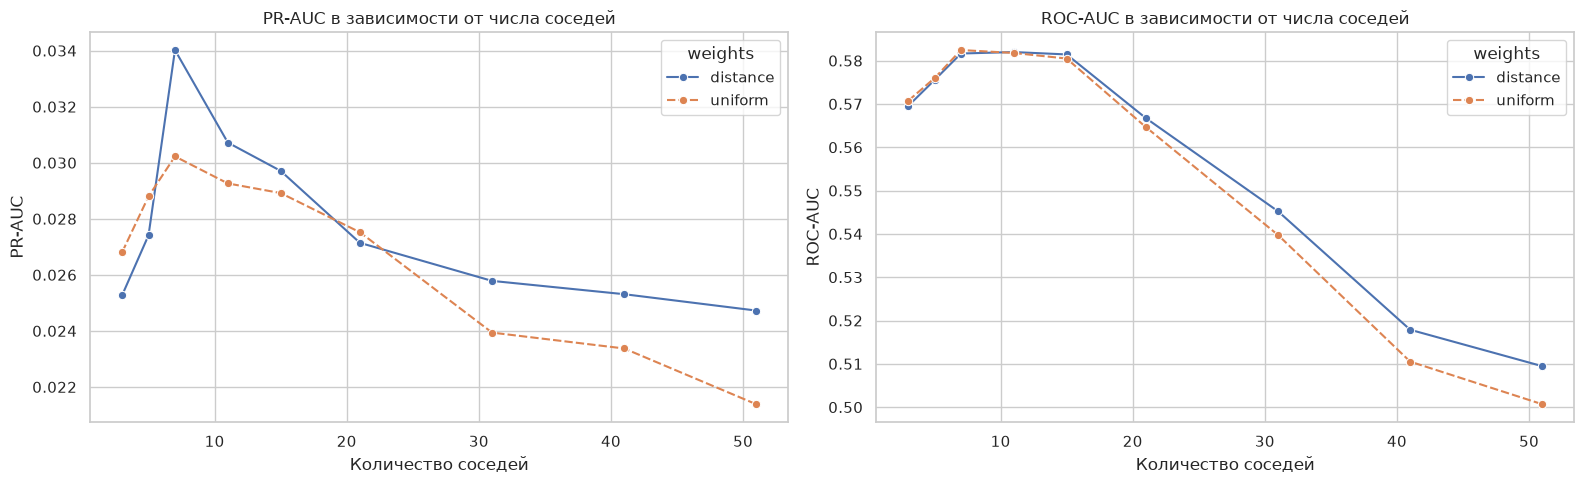

In [24]:
fig, axes = plt.subplots(
    1,
    2,
    figsize=(16, 5)
)

sns.lineplot(
    data=validation_results_df,
    x="n_neighbors",
    y="pr_auc",
    hue="weights",
    style="weights",
    marker="o",
    ax=axes[0]
)

axes[0].set_title(
    "PR-AUC в зависимости от числа соседей"
)
axes[0].set_xlabel(
    "Количество соседей"
)
axes[0].set_ylabel("PR-AUC")

sns.lineplot(
    data=validation_results_df,
    x="n_neighbors",
    y="roc_auc",
    hue="weights",
    style="weights",
    marker="o",
    ax=axes[1]
)

axes[1].set_title(
    "ROC-AUC в зависимости от числа соседей"
)
axes[1].set_xlabel(
    "Количество соседей"
)
axes[1].set_ylabel("ROC-AUC")

plt.tight_layout()
plt.show()

Выбор параметров модели

In [25]:
best_validation_result = (
    validation_results_df.iloc[0]
)

BEST_N_NEIGHBORS = int(
    best_validation_result[
        "n_neighbors"
    ]
)

BEST_WEIGHTS = (
    best_validation_result[
        "weights"
    ]
)

print("Лучшие параметры на validation:")
print(
    "Количество соседей:",
    BEST_N_NEIGHBORS
)
print(
    "Взвешивание:",
    BEST_WEIGHTS
)
print(
    f"PR-AUC: "
    f"{best_validation_result['pr_auc']:.4f}"
)
print(
    f"ROC-AUC: "
    f"{best_validation_result['roc_auc']:.4f}"
)

Лучшие параметры на validation:
Количество соседей: 7
Взвешивание: distance
PR-AUC: 0.0340
ROC-AUC: 0.5816


### Вывод по подбору KNN

Масштабирование улучшило способность KNN ранжировать наблюдения по риску. Поэтому итоговая модель использует стандартизированные числовые признаки.

Лучшее значение количества соседей выбиралось по PR-AUC на validation-выборке. PR-AUC используется как основной критерий, поскольку положительный класс составляет менее 2% наблюдений.

Лучшей оказалась модель примерно с 7 соседями и взвешиванием по расстоянию. Более близкие объекты в такой модели оказывают большее влияние на результат.

При стандартном пороге 0,5 значения Precision, Recall и F1 остаются низкими. Это не означает, что модель полностью бесполезна: сначала необходимо исследовать вероятности и подобрать более низкий порог, соответствующий бизнес-задаче раннего обнаружения поломок.

Невысокий PR-AUC также показывает, что доступные признаки слабо отделяют будущие поломки от нормальных состояний. Этот результат необходимо честно учитывать при интерпретации модели.

Получение вероятностей на validation

In [26]:
best_validation_model = validation_models[
    (
        BEST_N_NEIGHBORS,
        BEST_WEIGHTS
    )
]

validation_probability = (
    best_validation_model
    .predict_proba(
        X_validation
    )[:, 1]
)

validation_probability_df = pd.DataFrame({
    "y_true": y_validation.values,
    "failure_probability": validation_probability
})

display(
    validation_probability_df.head(10)
)

,y_true,failure_probability
0,0,0.0000
1,0,0.0000
2,0,0.0000
3,0,0.0000
4,0,0.4428
5,0,0.0000
6,0,0.0000
7,0,0.0000
8,0,0.4379
9,0,0.0000


In [27]:
display(
    validation_probability_df[
        "failure_probability"
    ].describe().to_frame()
)

print(
    "Максимальная вероятность:",
    f"{validation_probability.max():.4f}"
)

print(
    "Количество различных вероятностей:",
    validation_probability_df[
        "failure_probability"
    ].nunique()
)

print(
    "Количество нулевых вероятностей:",
    (
        validation_probability_df[
            "failure_probability"
        ] == 0
    ).sum()
)

,failure_probability
count,2315.0000
mean,0.0279
std,0.0942
min,0.0000
25%,0.0000
50%,0.0000
75%,0.0000
max,0.6143


Максимальная вероятность: 0.6143
Количество различных вероятностей: 238
Количество нулевых вероятностей: 2078


Precision–Recall Curve

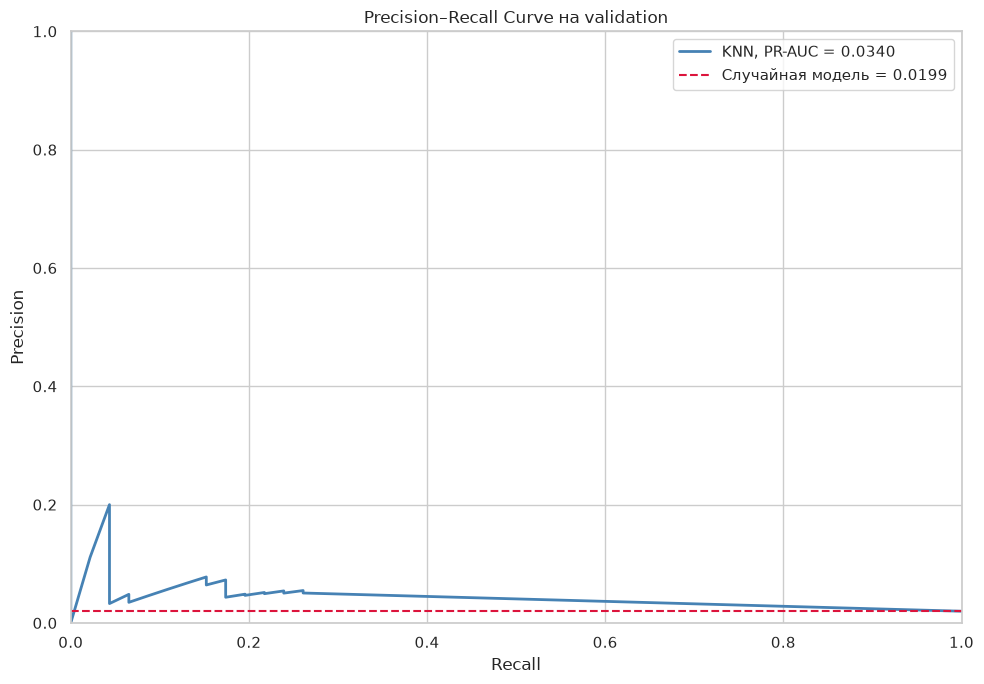

In [28]:
precision_values, recall_values, pr_thresholds = (
    precision_recall_curve(
        y_validation,
        validation_probability
    )
)

validation_pr_auc = (
    average_precision_score(
        y_validation,
        validation_probability
    )
)

class_prevalence = (
    y_validation.mean()
)

plt.figure(figsize=(10, 7))

plt.plot(
    recall_values,
    precision_values,
    color="steelblue",
    linewidth=2,
    label=(
        f"KNN, PR-AUC = "
        f"{validation_pr_auc:.4f}"
    )
)

plt.axhline(
    y=class_prevalence,
    color="crimson",
    linestyle="--",
    label=(
        f"Случайная модель = "
        f"{class_prevalence:.4f}"
    )
)

plt.title(
    "Precision–Recall Curve на validation"
)
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.xlim(0, 1)
plt.ylim(0, 1)
plt.legend()
plt.tight_layout()
plt.show()

### Интерпретация Precision–Recall Curve

Precision–Recall Curve показывает компромисс между двумя показателями:

- `Recall` — какую долю настоящих поломок обнаруживает модель;
- `Precision` — какая доля предупреждений модели действительно соответствует поломкам.

Горизонтальная пунктирная линия соответствует доле положительного класса. Она показывает качество случайного классификатора.

PR-AUC модели выше базовой доли положительного класса, однако остаётся низким. Следовательно, модель обнаружила некоторую зависимость, но разделение классов является слабым.

ROC-кривая

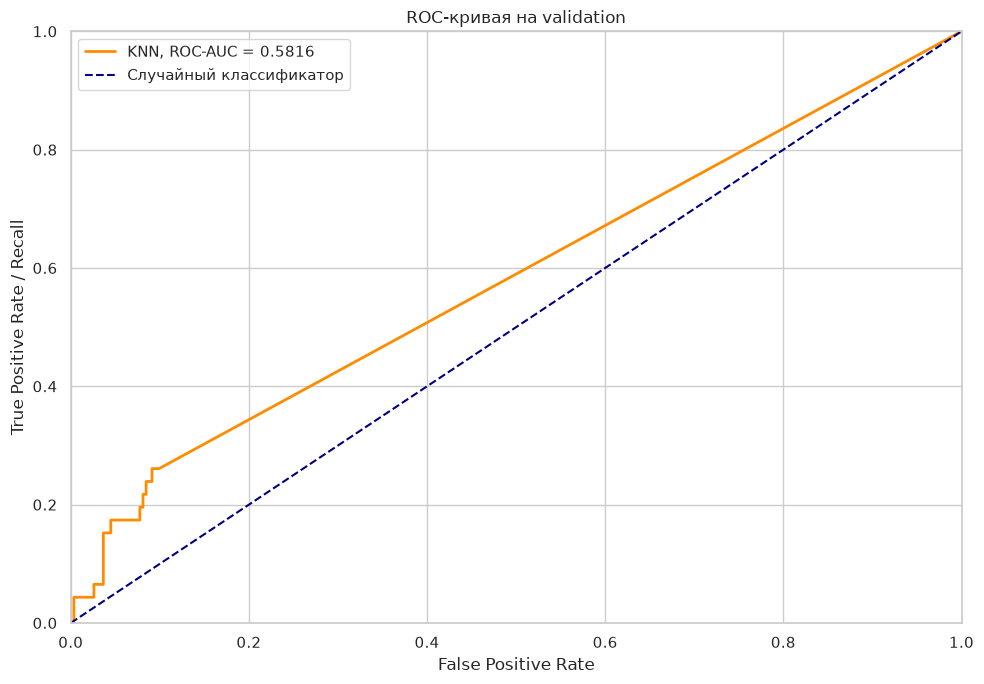

In [29]:
false_positive_rate, true_positive_rate, roc_thresholds = (
    roc_curve(
        y_validation,
        validation_probability
    )
)

validation_roc_auc = roc_auc_score(
    y_validation,
    validation_probability
)

plt.figure(figsize=(10, 7))

plt.plot(
    false_positive_rate,
    true_positive_rate,
    color="darkorange",
    linewidth=2,
    label=(
        f"KNN, ROC-AUC = "
        f"{validation_roc_auc:.4f}"
    )
)

plt.plot(
    [0, 1],
    [0, 1],
    color="navy",
    linestyle="--",
    label="Случайный классификатор"
)

plt.title("ROC-кривая на validation")
plt.xlabel(
    "False Positive Rate"
)
plt.ylabel(
    "True Positive Rate / Recall"
)
plt.xlim(0, 1)
plt.ylim(0, 1)
plt.legend()
plt.tight_layout()
plt.show()

### Интерпретация ROC-кривой

ROC-AUC показывает, насколько хорошо модель ранжирует положительные наблюдения выше отрицательных независимо от выбранного порога.

Значение ROC-AUC около 0,58 лишь немного выше 0,5, соответствующего случайному классификатору. Это подтверждает, что выбранные признаки слабо отделяют будущие поломки от нормальных состояний оборудования.

Поиск порога с максимальным F1

In [30]:
precision_for_threshold = (
    precision_values[:-1]
)

recall_for_threshold = (
    recall_values[:-1]
)

f1_for_threshold = (
    2
    * precision_for_threshold
    * recall_for_threshold
    / (
        precision_for_threshold
        + recall_for_threshold
        + 1e-12
    )
)

best_f1_index = np.argmax(
    f1_for_threshold
)

MAX_F1_THRESHOLD = float(
    pr_thresholds[best_f1_index]
)

max_validation_f1 = float(
    f1_for_threshold[best_f1_index]
)

precision_at_max_f1 = float(
    precision_for_threshold[
        best_f1_index
    ]
)

recall_at_max_f1 = float(
    recall_for_threshold[
        best_f1_index
    ]
)

print(
    f"Порог максимального F1: "
    f"{MAX_F1_THRESHOLD:.4f}"
)

print(
    f"Precision: "
    f"{precision_at_max_f1:.4f}"
)

print(
    f"Recall: "
    f"{recall_at_max_f1:.4f}"
)

print(
    f"F1: "
    f"{max_validation_f1:.4f}"
)

Порог максимального F1: 0.3083
Precision: 0.0778
Recall: 0.1522
F1: 0.1029


График метрик в зависимости от порога

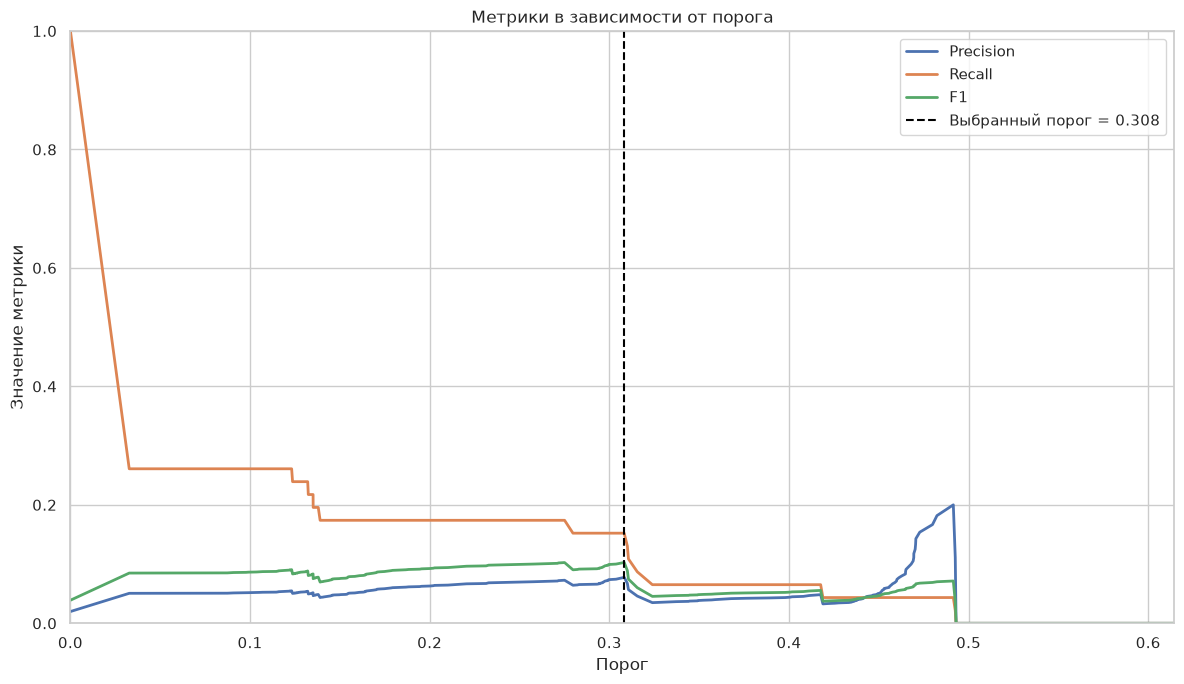

In [31]:
plt.figure(figsize=(12, 7))

plt.plot(
    pr_thresholds,
    precision_for_threshold,
    label="Precision",
    linewidth=2
)

plt.plot(
    pr_thresholds,
    recall_for_threshold,
    label="Recall",
    linewidth=2
)

plt.plot(
    pr_thresholds,
    f1_for_threshold,
    label="F1",
    linewidth=2
)

plt.axvline(
    x=MAX_F1_THRESHOLD,
    color="black",
    linestyle="--",
    label=(
        f"Выбранный порог = "
        f"{MAX_F1_THRESHOLD:.3f}"
    )
)

plt.title(
    "Метрики в зависимости от порога"
)
plt.xlabel("Порог")
plt.ylabel("Значение метрики")
plt.xlim(
    pr_thresholds.min(),
    pr_thresholds.max()
)
plt.ylim(0, 1)
plt.legend()
plt.tight_layout()
plt.show()

Таблица порогов

In [32]:
candidate_thresholds = sorted(
    set([
        0.00,
        0.01,
        0.05,
        0.10,
        0.15,
        0.20,
        0.25,
        0.30,
        round(
            MAX_F1_THRESHOLD,
            6
        ),
        0.40,
        0.50
    ])
)

threshold_results = []

for threshold in candidate_thresholds:

    metrics = (
        calculate_classification_metrics(
            y_validation,
            validation_probability,
            threshold=threshold
        )
    )

    threshold_results.append(
        metrics
    )

threshold_results_df = pd.DataFrame(
    threshold_results
)

display(
    threshold_results_df.style.format({
        "threshold": "{:.4f}",
        "accuracy": "{:.4f}",
        "precision": "{:.4f}",
        "recall": "{:.4f}",
        "f1": "{:.4f}",
        "roc_auc": "{:.4f}",
        "pr_auc": "{:.4f}"
    })
)

,threshold,accuracy,precision,recall,f1,roc_auc,pr_auc,predicted_positives
0,0.0000,0.0199,0.0199,1.0000,0.0390,0.5816,0.0340,2315
1,0.0100,0.8881,0.0506,0.2609,0.0848,0.5816,0.0340,237
2,0.0500,0.8886,0.0508,0.2609,0.0851,0.5816,0.0340,236
3,0.1000,0.8907,0.0519,0.2609,0.0866,0.5816,0.0340,231
4,0.1500,0.9158,0.0485,0.1739,0.0758,0.5816,0.0340,165
5,0.2000,0.9322,0.0630,0.1739,0.0925,0.5816,0.0340,127
6,0.2500,0.9374,0.0696,0.1739,0.0994,0.5816,0.0340,115
7,0.3000,0.9456,0.0745,0.1522,0.1000,0.5816,0.0340,94
8,0.3083,0.9473,0.0778,0.1522,0.1029,0.5816,0.0340,90
9,0.4000,0.9533,0.0441,0.0652,0.0526,0.5816,0.0340,68


Проверка бизнес-порога Recall ≥ 70%

In [33]:
minimum_required_recall = 0.70

business_mask = (
    (recall_for_threshold >= minimum_required_recall)
    & (pr_thresholds > 0)
)

if business_mask.any():

    business_indexes = np.flatnonzero(
        business_mask
    )

    best_business_index = (
        business_indexes[
            np.argmax(
                precision_for_threshold[
                    business_mask
                ]
            )
        ]
    )

    business_threshold = float(
        pr_thresholds[
            best_business_index
        ]
    )

    business_precision = float(
        precision_for_threshold[
            best_business_index
        ]
    )

    business_recall = float(
        recall_for_threshold[
            best_business_index
        ]
    )

    print(
        "Найден подходящий бизнес-порог."
    )
    print(
        f"Порог: {business_threshold:.4f}"
    )
    print(
        f"Precision: {business_precision:.4f}"
    )
    print(
        f"Recall: {business_recall:.4f}"
    )

else:
    business_threshold = None

    print(
        "Положительного порога, обеспечивающего "
        "Recall не ниже 70%, не найдено."
    )

Положительного порога, обеспечивающего Recall не ниже 70%, не найдено.


Фиксация итогового порога

In [34]:
SELECTED_THRESHOLD = (
    MAX_F1_THRESHOLD
)

print(
    "Зафиксированный порог:",
    f"{SELECTED_THRESHOLD:.4f}"
)

Зафиксированный порог: 0.3083


## Обоснование порога классификации

В задаче предиктивного обслуживания пропуск настоящей поломки обычно опаснее ложного предупреждения. Поэтому первоначально рассматривался порог, обеспечивающий Recall не ниже 70%.

Однако KNN не смог обеспечить такой Recall ни при одном положительном пороге. Recall, равный 100%, достигается только при пороге 0, когда модель относит к поломкам абсолютно все наблюдения. Такой классификатор не имеет практической ценности.

Поэтому для учебной модели выбран порог приблизительно 0,308, при котором на validation-выборке достигается максимальный F1-score.

При этом:

- Precision составляет около 7,8%;
- Recall — около 15,2%;
- F1-score — около 10,3%.

Порог ниже стандартного значения 0,5, поскольку положительный класс встречается редко и рассчитанные моделью вероятности в основном невысоки.

Даже после изменения порога Recall остаётся недостаточным для промышленного применения. Следовательно, выбранный порог является лучшим компромиссом для текущей модели, но не решает проблему слабой разделимости классов.

Обучение итоговой модели

In [35]:
final_model = create_knn_pipeline(
    n_neighbors=BEST_N_NEIGHBORS,
    scale_numeric=True,
    weights=BEST_WEIGHTS
)

final_model.fit(
    X_train,
    y_train
)

print("Итоговая модель обучена.")
print(
    "Количество соседей:",
    BEST_N_NEIGHBORS
)
print(
    "Взвешивание:",
    BEST_WEIGHTS
)
print(
    "Обучающих наблюдений:",
    len(X_train)
)

Итоговая модель обучена.
Количество соседей: 7
Взвешивание: distance
Обучающих наблюдений: 13728


Получение тестовых прогнозов

In [36]:
test_probability = (
    final_model
    .predict_proba(
        X_test
    )[:, 1]
)

test_prediction_default = (
    test_probability >= 0.5
).astype(int)

test_prediction_selected = (
    test_probability
    >= SELECTED_THRESHOLD
).astype(int)

test_predictions_df = pd.DataFrame({
    "prediction_time": (
        test_df[
            "prediction_time"
        ].values
    ),
    "y_true": y_test.values,
    "failure_probability": (
        test_probability
    ),
    "prediction_threshold_05": (
        test_prediction_default
    ),
    "prediction_selected_threshold": (
        test_prediction_selected
    )
})

display(
    test_predictions_df.head(10)
)

,prediction_time,y_true,failure_probability,prediction_threshold_05,prediction_selected_threshold
0,2025-05-27 22:00:00,0,0.0000,0,0
1,2025-05-27 23:00:00,0,0.0000,0,0
2,2025-05-28 04:00:00,0,0.0000,0,0
3,2025-05-28 04:00:00,0,0.6292,1,1
4,2025-05-28 04:00:00,0,0.0000,0,0
5,2025-05-28 04:00:00,0,0.0000,0,0
6,2025-05-28 04:00:00,0,0.0000,0,0
7,2025-05-28 05:00:00,0,0.0000,0,0
8,2025-05-28 05:00:00,0,0.0000,0,0
9,2025-05-28 05:00:00,0,0.0000,0,0


Сравнение двух порогов

In [37]:
default_threshold_metrics = (
    calculate_classification_metrics(
        y_test,
        test_probability,
        threshold=0.5
    )
)

selected_threshold_metrics = (
    calculate_classification_metrics(
        y_test,
        test_probability,
        threshold=SELECTED_THRESHOLD
    )
)

test_metrics_df = pd.DataFrame([
    {
        "threshold_name": (
            "Стандартный порог"
        ),
        **default_threshold_metrics
    },
    {
        "threshold_name": (
            "Выбранный по validation"
        ),
        **selected_threshold_metrics
    }
])

display(
    test_metrics_df.style.format({
        "threshold": "{:.4f}",
        "accuracy": "{:.4f}",
        "precision": "{:.4f}",
        "recall": "{:.4f}",
        "f1": "{:.4f}",
        "roc_auc": "{:.4f}",
        "pr_auc": "{:.4f}"
    })
)

,threshold_name,threshold,accuracy,precision,recall,f1,roc_auc,pr_auc,predicted_positives
0,Стандартный порог,0.5000,0.9736,0.0000,0.0000,0.0000,0.4993,0.0113,55
1,Выбранный по validation,0.3083,0.9576,0.0000,0.0000,0.0000,0.4993,0.0113,114


Матрицы ошибок

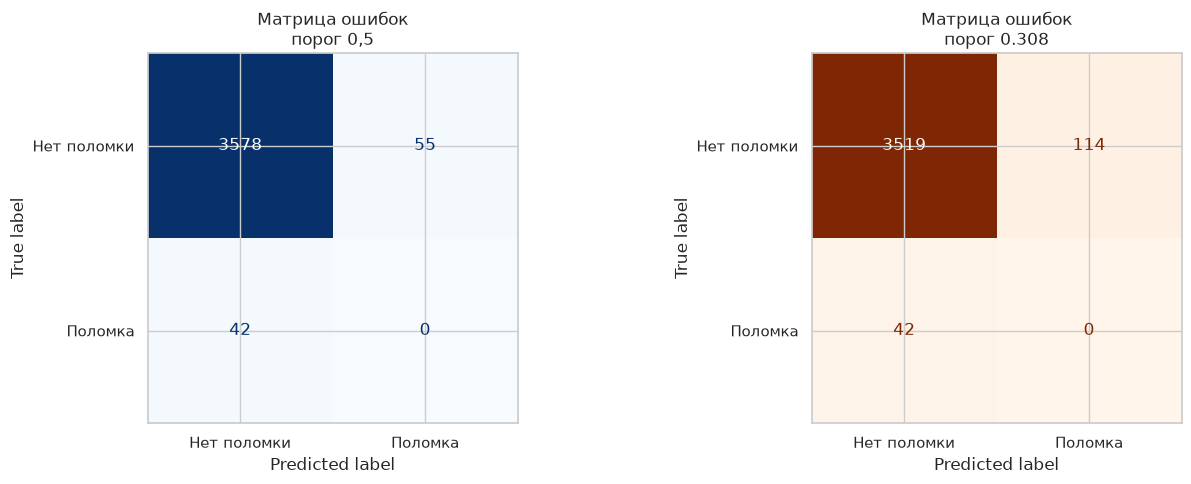

In [38]:
default_confusion_matrix = (
    confusion_matrix(
        y_test,
        test_prediction_default
    )
)

selected_confusion_matrix = (
    confusion_matrix(
        y_test,
        test_prediction_selected
    )
)

fig, axes = plt.subplots(
    1,
    2,
    figsize=(14, 5)
)

ConfusionMatrixDisplay(
    confusion_matrix=(
        default_confusion_matrix
    ),
    display_labels=[
        "Нет поломки",
        "Поломка"
    ]
).plot(
    ax=axes[0],
    cmap="Blues",
    colorbar=False
)

axes[0].set_title(
    "Матрица ошибок\nпорог 0,5"
)

ConfusionMatrixDisplay(
    confusion_matrix=(
        selected_confusion_matrix
    ),
    display_labels=[
        "Нет поломки",
        "Поломка"
    ]
).plot(
    ax=axes[1],
    cmap="Oranges",
    colorbar=False
)

axes[1].set_title(
    "Матрица ошибок\n"
    f"порог {SELECTED_THRESHOLD:.3f}"
)

plt.tight_layout()
plt.show()

In [39]:
def confusion_matrix_table(
    y_true,
    y_prediction,
    threshold_name
):
    tn, fp, fn, tp = (
        confusion_matrix(
            y_true,
            y_prediction
        ).ravel()
    )

    return {
        "threshold": threshold_name,
        "true_negative": tn,
        "false_positive": fp,
        "false_negative": fn,
        "true_positive": tp
    }


confusion_results_df = pd.DataFrame([
    confusion_matrix_table(
        y_test,
        test_prediction_default,
        "0.5"
    ),
    confusion_matrix_table(
        y_test,
        test_prediction_selected,
        f"{SELECTED_THRESHOLD:.3f}"
    )
])

display(confusion_results_df)

,threshold,true_negative,false_positive,false_negative,true_positive
0,0.5,3578,55,42,0
1,0.308,3519,114,42,0


То есть модель:
- сформировала 114 ложных предупреждений;
- пропустила все 42 реальные поломки;
- не обнаружила ни одной настоящей поломки.

Classification report

In [40]:
print(
    classification_report(
        y_test,
        test_prediction_selected,
        target_names=[
            "Нет поломки",
            "Поломка"
        ],
        zero_division=0
    )
)

              precision    recall  f1-score   support

 Нет поломки       0.99      0.97      0.98      3633
     Поломка       0.00      0.00      0.00        42

    accuracy                           0.96      3675
   macro avg       0.49      0.48      0.49      3675
weighted avg       0.98      0.96      0.97      3675



Итоговые PR- и ROC-кривые

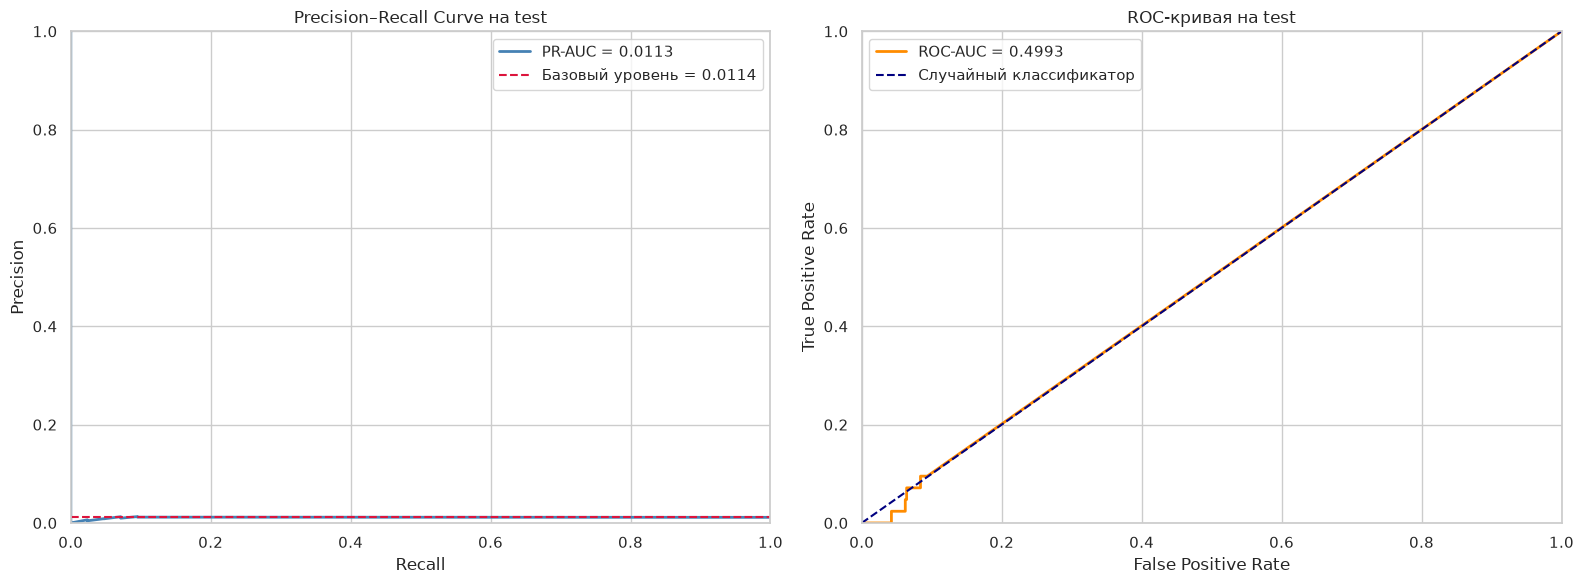

In [41]:
test_precision, test_recall, _ = (
    precision_recall_curve(
        y_test,
        test_probability
    )
)

test_fpr, test_tpr, _ = (
    roc_curve(
        y_test,
        test_probability
    )
)

test_pr_auc = (
    average_precision_score(
        y_test,
        test_probability
    )
)

test_roc_auc = (
    roc_auc_score(
        y_test,
        test_probability
    )
)

test_prevalence = (
    y_test.mean()
)

fig, axes = plt.subplots(
    1,
    2,
    figsize=(16, 6)
)

axes[0].plot(
    test_recall,
    test_precision,
    color="steelblue",
    linewidth=2,
    label=(
        f"PR-AUC = "
        f"{test_pr_auc:.4f}"
    )
)

axes[0].axhline(
    y=test_prevalence,
    color="crimson",
    linestyle="--",
    label=(
        f"Базовый уровень = "
        f"{test_prevalence:.4f}"
    )
)

axes[0].set_title(
    "Precision–Recall Curve на test"
)
axes[0].set_xlabel("Recall")
axes[0].set_ylabel("Precision")
axes[0].set_xlim(0, 1)
axes[0].set_ylim(0, 1)
axes[0].legend()

axes[1].plot(
    test_fpr,
    test_tpr,
    color="darkorange",
    linewidth=2,
    label=(
        f"ROC-AUC = "
        f"{test_roc_auc:.4f}"
    )
)

axes[1].plot(
    [0, 1],
    [0, 1],
    color="navy",
    linestyle="--",
    label="Случайный классификатор"
)

axes[1].set_title(
    "ROC-кривая на test"
)
axes[1].set_xlabel(
    "False Positive Rate"
)
axes[1].set_ylabel(
    "True Positive Rate"
)
axes[1].set_xlim(0, 1)
axes[1].set_ylim(0, 1)
axes[1].legend()

plt.tight_layout()
plt.show()

Сравнение с константным прогнозом

In [42]:
baseline_prediction = np.zeros(
    len(y_test),
    dtype=int
)

baseline_accuracy = accuracy_score(
    y_test,
    baseline_prediction
)

print(
    "Accuracy константной модели:",
    f"{baseline_accuracy:.4f}"
)

print(
    "Accuracy KNN, порог 0.5:",
    f"{default_threshold_metrics['accuracy']:.4f}"
)

print(
    "Accuracy KNN, выбранный порог:",
    f"{selected_threshold_metrics['accuracy']:.4f}"
)

Accuracy константной модели: 0.9886
Accuracy KNN, порог 0.5: 0.9736
Accuracy KNN, выбранный порог: 0.9576


Константная модель имеет более высокую accuracy, но также не обнаруживает поломки. Это показывает, почему accuracy нельзя использовать как основной показатель.

Дополнительный анализ низких порогов

In [43]:
additional_thresholds = [
    0.05,
    0.10,
    0.15,
    0.20,
    0.25,
    SELECTED_THRESHOLD,
    0.50
]

additional_threshold_results = []

for threshold in additional_thresholds:

    metrics = (
        calculate_classification_metrics(
            y_test,
            test_probability,
            threshold=threshold
        )
    )

    additional_threshold_results.append(
        metrics
    )

additional_threshold_results_df = (
    pd.DataFrame(
        additional_threshold_results
    )
)

display(
    additional_threshold_results_df.style.format({
        "threshold": "{:.4f}",
        "accuracy": "{:.4f}",
        "precision": "{:.4f}",
        "recall": "{:.4f}",
        "f1": "{:.4f}",
        "roc_auc": "{:.4f}",
        "pr_auc": "{:.4f}"
    })
)

,threshold,accuracy,precision,recall,f1,roc_auc,pr_auc,predicted_positives
0,0.0500,0.8971,0.0116,0.0952,0.0207,0.4993,0.0113,344
1,0.1000,0.8990,0.0119,0.0952,0.0211,0.4993,0.0113,337
2,0.1500,0.9371,0.0052,0.0238,0.0086,0.4993,0.0113,191
3,0.2000,0.9467,0.0064,0.0238,0.0101,0.4993,0.0113,156
4,0.2500,0.9494,0.0000,0.0000,0.0000,0.4993,0.0113,144
5,0.3083,0.9576,0.0000,0.0000,0.0000,0.4993,0.0113,114
6,0.5000,0.9736,0.0000,0.0000,0.0000,0.4993,0.0113,55


При пороге около 0.10 модель ориентировочно:
- обнаружит 4 из 42 поломок;
- Recall составит около 9,5%;
- Precision — около 1,2%;
- сформирует более 300 предупреждений.
Даже этот порог не даёт приемлемого результата.

## Итоговая оценка модели

Итоговая модель KNN была обучена на 13 728 наблюдениях и проверена на 3 675 более поздних наблюдениях. В тестовой выборке содержалось 42 случая будущей поломки.

Для модели использовались:

- стандартизация числовых признаков;
- заполнение пропусков медианой;
- One-Hot Encoding типа оборудования;
- 7 ближайших соседей;
- взвешивание соседей по расстоянию;
- порог около 0,308, выбранный на validation по максимальному F1.

На validation-выборке модель показала ROC-AUC около 0,58 и PR-AUC около 0,034. Это соответствовало слабой, но существующей способности ранжировать наблюдения по риску.

На тестовой выборке результат не воспроизвёлся:

- ROC-AUC оказался около 0,50;
- PR-AUC — около 0,011;
- Precision, Recall и F1 при выбранном пороге равны нулю;
- все 42 реальные поломки были пропущены;
- модель сформировала более 100 ложных предупреждений.

ROC-AUC около 0,5 означает, что на будущем временном периоде модель ранжирует наблюдения практически на уровне случайного классификатора. PR-AUC примерно совпадает с долей положительного класса.

Высокая accuracy не свидетельствует о хорошем качестве. Константный классификатор, всегда предсказывающий отсутствие поломки, имеет accuracy около 98,86%, поскольку положительный класс встречается очень редко.

Таким образом, полученная модель KNN не подходит для практического прогнозирования поломок.

## Содержательная интерпретация результата

Основная причина низкого качества заключается не только в выборе алгоритма, но и в структуре данных:

1. Будущие поломки составляют около 1,55% всей выборки.
2. Распределения доступных признаков для классов 0 и 1 значительно перекрываются.
3. Средние значения температуры, мощности, возраста и количества выходов за границы мало различаются между классами.
4. В тестовом периоде доля поломок ниже, чем в обучающем периоде.
5. Закономерности validation-периода не перенеслись на более поздний test-период.
6. KNN чувствителен к неинформативным признакам, размерности пространства и локальным изменениям распределения данных.

С практической точки зрения текущие показатели датчиков не позволяют надёжно предсказать поломку за 6 часов с помощью KNN.

Для дальнейшего улучшения можно:

- сформировать временные тренды и изменения показателей за несколько часов;
- рассчитать отклонение показаний от нормального режима конкретной машины;
- добавить скорость изменения температуры, мощности и вибрации;
- обработать дисбаланс только внутри обучающей выборки;
- проверить логистическую регрессию, деревья решений и случайный лес;
- отдельно оценить качество для разных типов оборудования;
- увеличить количество зарегистрированных случаев поломок.

Несмотря на неудовлетворительное прикладное качество, в работе выполнен полный цикл решения задачи классификации: подготовка данных, масштабирование, обучение KNN, подбор параметров и порога, построение ROC- и PR-кривых, матрицы ошибок и расчёт метрик.